# Feature Engineering

Builds the full feature matrix for `aggregate_cpu_utilization` forecasting.

Feature groups:
1. **Lag features** — steps 1, 2, 3, 6, 12, 24
2. **Rolling stats** — mean & std over windows 3, 6, 12
3. **Per-category CPU series** — mean avg_cpu per timestamp for each category
4. **Deployment-level metadata** — static scalars (mean dep size, mean/std dep avg_cpu, category fractions)
5. **Calendar proxy** — hour-of-trace

> **active_vm_count is a flat constant (10,000)** — confirmed by EDA. No features needed for it.

In [1]:
from pathlib import Path
import sys
sys.path.insert(0, '../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from cwfc.data import load_raw, build_targets
from cwfc.features import build_category_ts, build_fleet_ts, build_features, split_features

TRAIN_OBS = 110

meta, cpu = load_raw(Path('../challenge_data'))
targets   = build_targets(cpu)
cat_ts    = build_category_ts(cpu, meta)
fleet_ts  = build_fleet_ts(cpu, meta)


## 1. Lag & rolling features on `aggregate_cpu_utilization`

In [2]:
# Build the feature matrix
feat_df = build_features(targets, cat_ts, meta, fleet_ts=fleet_ts)
print('Feature matrix shape:', feat_df.shape)
print('Columns:', feat_df.columns.tolist())


Feature matrix shape: (134, 12)
Columns: ['timestamp', 'aggregate_cpu_utilization', 'aggregate_cpu_utilization_lag1', 'aggregate_cpu_utilization_lag2', 'aggregate_cpu_utilization_lag3', 'aggregate_cpu_utilization_diff1', 'aggregate_cpu_utilization_roll3_mean', 'aggregate_cpu_utilization_roll6_mean', 'cpu_Delay-insensitive_lag1', 'cpu_Interactive_lag1', 'cpu_Unknown_lag1', 'core_weighted_cpu_lag1']


In [3]:
# First few rows have NaN because lag features need warm-up rows
nan_rows = feat_df.isnull().any(axis=1).sum()
print(f'Rows with NaN: {nan_rows} (these are dropped from training only)')
print(f'Usable training rows: {TRAIN_OBS - nan_rows}')


Rows with NaN: 6 (these are dropped from training only)
Usable training rows: 104


In [4]:
# How well do past CPU values predict the next value?
train_clean = feat_df.iloc[:TRAIN_OBS].dropna()
target_col  = 'aggregate_cpu_utilization'
lag_cols    = ['aggregate_cpu_utilization_lag1', 'aggregate_cpu_utilization_lag2', 'aggregate_cpu_utilization_lag3']

corrs = train_clean[lag_cols].corrwith(train_clean[target_col])
corrs.index = ['lag 1 (5 min)', 'lag 2 (10 min)', 'lag 3 (15 min)']
print('Correlation of lagged CPU with current CPU:')
print(corrs.round(3).to_string())


Correlation of lagged CPU with current CPU:
lag 1 (5 min)     0.690
lag 2 (10 min)    0.628
lag 3 (15 min)    0.686


In [5]:
# Rolling means vs target
roll_cols = ['aggregate_cpu_utilization_roll3_mean', 'aggregate_cpu_utilization_roll6_mean']
roll_corrs = train_clean[roll_cols].corrwith(train_clean[target_col])
roll_corrs.index = ['roll 3 (15-min avg)', 'roll 6 (30-min avg)']
print('Correlation of rolling means with current CPU:')
print(roll_corrs.round(3).to_string())


Correlation of rolling means with current CPU:
roll 3 (15-min avg)    0.764
roll 6 (30-min avg)    0.715


## 2. Per-category CPU series as features

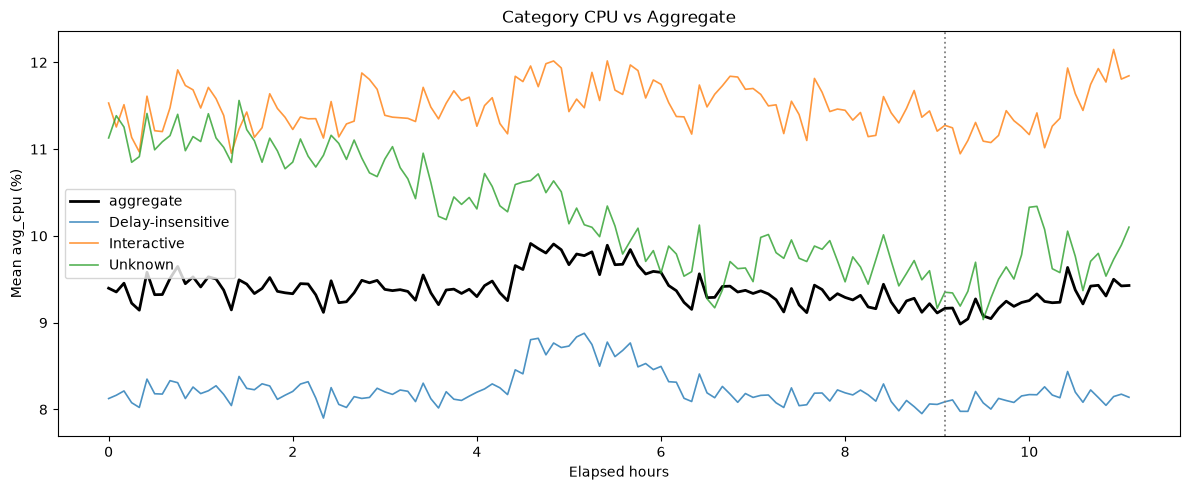

In [6]:
# Plot each VM category's CPU over time
cat_cols  = [c for c in cat_ts.columns if c.startswith('cpu_')]
hour      = targets['timestamp'] / 3600

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(hour, targets['aggregate_cpu_utilization'], color='black', lw=2, label='aggregate')
for col in cat_cols:
    ax.plot(hour, cat_ts[col], lw=1.2, alpha=0.8, label=col.replace('cpu_', ''))
ax.axvline(targets.iloc[TRAIN_OBS - 1]['timestamp'] / 3600, color='gray', ls=':', lw=1.3)
ax.set_title('Category CPU vs Aggregate')
ax.set_xlabel('Elapsed hours')
ax.set_ylabel('Mean avg_cpu (%)')
ax.legend()
plt.tight_layout()
plt.show()


In [7]:
# How well does each category's lagged CPU predict the aggregate?
cat_lag_cols = ['cpu_Delay-insensitive_lag1', 'cpu_Interactive_lag1', 'cpu_Unknown_lag1']
cat_corrs = train_clean[cat_lag_cols].corrwith(train_clean[target_col])
cat_corrs.index = ['Delay-insensitive lag1', 'Interactive lag1', 'Unknown lag1']
print('Category lag-1 correlation with aggregate CPU:')
print(cat_corrs.round(3).to_string())


Category lag-1 correlation with aggregate CPU:
Delay-insensitive lag1    0.722
Interactive lag1          0.369
Unknown lag1              0.195


## 3. Final feature matrix summary


In [8]:
# Split into train/test feature matrices
X_train, X_test, y_train, y_test = split_features(feat_df, TRAIN_OBS)

print('X_train shape:', X_train.shape)
print('X_test  shape:', X_test.shape)
print('y_train mean:', round(y_train.mean(), 3), ' std:', round(y_train.std(), 3))
print('NaN in X_train:', X_train.isnull().sum().sum())
print('NaN in X_test:', X_test.isnull().sum().sum())


X_train shape: (104, 10)
X_test  shape: (24, 10)
y_train mean: 9.417  std: 0.196
NaN in X_train: 0
NaN in X_test: 0


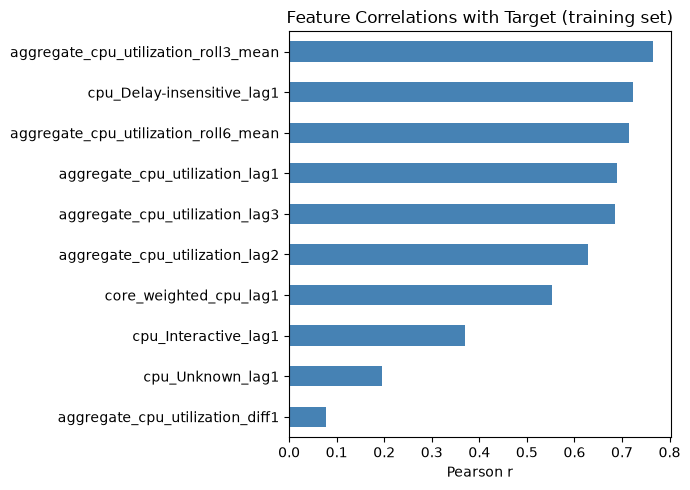

aggregate_cpu_utilization_roll3_mean    0.764
cpu_Delay-insensitive_lag1              0.722
aggregate_cpu_utilization_roll6_mean    0.715
aggregate_cpu_utilization_lag1          0.690
aggregate_cpu_utilization_lag3          0.686
aggregate_cpu_utilization_lag2          0.628
core_weighted_cpu_lag1                  0.552
cpu_Interactive_lag1                    0.369
cpu_Unknown_lag1                        0.195
aggregate_cpu_utilization_diff1         0.077


In [9]:
# Which features correlate most with the target?
corr_with_target = (
    X_train.join(y_train)
    .corr()['aggregate_cpu_utilization']
    .drop('aggregate_cpu_utilization')
    .sort_values(key=abs, ascending=False)
)

fig, ax = plt.subplots(figsize=(7, 5))
colors = ['steelblue' if v >= 0 else 'tomato' for v in corr_with_target.values]
corr_with_target.plot.barh(ax=ax, color=colors)
ax.invert_yaxis()
ax.set_title('Feature Correlations with Target (training set)')
ax.set_xlabel('Pearson r')
plt.tight_layout()
plt.show()

print(corr_with_target.round(3).to_string())
